In [3]:
# Load Libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

In [4]:

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.13.0+cu130
CUDA available: True
CUDA version: 13.0
GPU: NVIDIA GeForce RTX 2060 SUPER


In [5]:
# Import CCIFAR10 Dataset
transform = transforms.Compose([transforms.ToTensor()]) # Convert pixel values to range [0.0, 1.0]
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

In [6]:
from prompt_toolkit.shortcuts import progress_bar
# Functions
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training Function
def train_model(model, train_loader, criterion, optimizer, epochs=10):

  for epoch in range(epochs):
    model.train()

    loss_per_epoch = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
      images = images.to(device)
      labels = labels.to(device)

      # zero grad
      optimizer.zero_grad()

      # forward pass
      outputs = model(images)

      #calculating loss on the output
      loss = criterion(outputs, labels)

      #grad calc w.r.t Loss func
      loss.backward()

       #update weights
      optimizer.step()

      # cumulate loss
      loss_per_epoch+=loss.item()

      # calculating accuracy
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

    epoch_loss = loss_per_epoch / len(train_loader)
    epoch_accuracy = 100 * (correct / total)

    print(f"Epoch [{epoch+1}/{epochs}], "
      f"Loss: {epoch_loss:.4f}, "
      f"Accuracy: {epoch_accuracy:.2f}%")

# Testing Function
def test_model(model, test_loader):

  # Evaluation mode on
  model.eval()

  correct = 0
  total = 0

  with torch.no_grad():

    for images, labels in test_loader:
      images = images.to(device)
      labels = labels.to(device)

      # forward pass
      outputs = model(images)

      # get the predicted class
      _, predicted = torch.max(outputs.data, 1)

      # calculating accuracy
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

  accuracy = 100 * (correct / total)
  print(f"Test Accuracy: {accuracy:.2f}%")

def adversarial_training(model, train_loader, attack, optimizer, criterion, adv_portion=0.5, epochs=3):

  for epoch in range(epochs):
    model.train()

    loss_per_epoch = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

    for images, labels in progress_bar:
      images = images.to(device)
      labels = labels.to(device)

      # Num of adv imgs to create in this batch
      num_adv = int(images.size(0) * adv_portion)

      # Generate adv examples
      x_adv_train = attack.generate(x=images[:num_adv].detach().cpu().numpy())

      # Convert adv imgs back into PyTorch tensors
      x_adv_train = torch.tensor(
          x_adv_train,
          dtype=torch.float32,
          device=device
      )

      # Create mixed batch of clean and adv imgs
      mixed_images = images.clone()
      mixed_images[:num_adv] = x_adv_train

      # zero grad
      optimizer.zero_grad()

      # forward pass
      outputs = model(mixed_images)

      #calculating loss on the output
      loss = criterion(outputs, labels)

      #grad calc w.r.t Loss func
      loss.backward()

      #update weights
      optimizer.step()

      # cumulate loss
      loss_per_epoch+=loss.item()

      # calculating accuracy
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

    epoch_loss = loss_per_epoch / len(train_loader)
    epoch_accuracy = 100 * (correct / total)

    print(f"Epoch [{epoch+1}/{epochs}], "
      f"Loss: {epoch_loss:.4f}, "
      f"Accuracy: {epoch_accuracy:.2f}%")

def distillation_training(t, s, train_loader, optimizer, temp=10, epochs=2):

  t.eval()

  for epoch in range(epochs):
    s.train()

    loss_per_epoch = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

    for images, labels in progress_bar:
      images = images.to(device)
      labels = labels.to(device)

      with torch.no_grad():
        t_outputs = t(images)
        t_soft = torch.softmax(t_outputs / temp, dim=1)

      s_outputs = s(images)
      s_log_soft = torch.log_softmax(s_outputs / temp, dim=1)

      loss = nn.KLDivLoss(reduction='batchmean')(s_log_soft, t_soft)

      loss = loss * (temp ** 2)

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      loss_per_epoch+=loss.item()

      # calculating accuracy
      _, predicted = torch.max(s_outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

    epoch_loss = loss_per_epoch / len(train_loader)
    epoch_accuracy = 100 * (correct / total)

    print(f"Epoch [{epoch+1}/{epochs}], "
      f"Loss: {epoch_loss:.4f}, "
      f"Accuracy: {epoch_accuracy:.2f}%")


In [7]:
# Dataloaders
batch_size = 128 # Feed the model the specified batch_size in parallel
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training images: {len(train_dataset)}")
print(f"Number of testing images: {len(test_dataset)}")
print(f"Number of classes: {train_dataset.classes}")

Number of training images: 50000
Number of testing images: 10000
Number of classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Training and Testing Model A and Model B

In [8]:
# Model A: ResNet18 (18-layer convolutional neural network)
from torchvision.models import resnet18
model_a = resnet18(weights=None) # not using ResNet's pretrained weight here
# Replace first conv due to difference b/w trained img sizes & CIFAR-10 img sizes
model_a.conv1 = nn.Conv2d(3,  # Number of channels (input)
                          64, # output channels
                          kernel_size=3,
                          stride=1,
                          padding=1,
                          bias=False)
model_a.maxpool = nn.Identity() # Prevent shrinkage on CIFAR-10 images as they're already small

# Make Resnet10 only predict 10 classes
model_a.fc = nn.Linear(model_a.fc.in_features, 10)

model_a = model_a.to(device) # Moved model onto T4 GPU (cuda) in Runtime settings
print("the device:", device)

the device: cuda


In [ ]:
# Train Model A
criterion = nn.CrossEntropyLoss()
optimizer_a = optim.Adam(model_a.parameters(), lr=0.001)

train_model(
    model_a,
    train_loader,
    criterion,
    optimizer_a,
    epochs=10
)

In [15]:
# Test Model A
test_model(model_a, test_loader)

Test Accuracy: 82.07%


In [18]:
# Model B: VGG16 (16-layer convolutional neural network)
from torchvision.models import vgg16

model_b = vgg16(weights=None) # not using VGG's pretrained weight here

# Change classfier (final one: layer 6) to represent 10 classes
model_b.classifier[6] = nn.Linear(
    model_b.classifier[6].in_features,
    10
)

model_b = model_b.to(device) # Moved model onto T4 GPU (cuda) in Runtime settings
print("the device:", device)

the device: cuda


In [19]:
# Train Model B
criterion = nn.CrossEntropyLoss()
optimizer_b = optim.Adam(model_b.parameters(), lr=0.0001) # Tuning: Changed from 0.001 to 0.0001 as it failed to learn on 0.001

train_model(
    model_b,
    train_loader,
    criterion,
    optimizer_b,
    epochs=10
)

Epoch [1/10], Loss: 1.9025, Accuracy: 24.76%
Epoch [2/10], Loss: 1.3861, Accuracy: 47.49%
Epoch [3/10], Loss: 1.0964, Accuracy: 60.43%
Epoch [4/10], Loss: 0.9169, Accuracy: 67.31%
Epoch [5/10], Loss: 0.7665, Accuracy: 72.91%
Epoch [6/10], Loss: 0.6347, Accuracy: 77.74%
Epoch [7/10], Loss: 0.5176, Accuracy: 82.02%
Epoch [8/10], Loss: 0.4122, Accuracy: 85.65%
Epoch [9/10], Loss: 0.3238, Accuracy: 88.83%
Epoch [10/10], Loss: 0.2523, Accuracy: 91.23%


In [20]:
#Test Model B
test_model(model_b, test_loader)

Test Accuracy: 72.13%


# Model Performance Observation
- Model A (ResNet18): 97.77% Training Accuracy, 82.07% Test Accuracy
- Model B (VGG16): 91.23% Training Accuracy, 72.13% Test Accuracy
- Model A had a higher test performance than Model B
- Hyperparameter tuning: VGG16 failed to learn with lr = 0.001 (the output was ~10% accuracy), however changing it to lr = 0.0001 made it successfully train.

Adversarial Attacks

In [21]:
!pip install adversarial-robustness-toolbox # install the toolbox

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 21.8 MB/s eta 0:00:00


Attack 1: C&W L2 Attack

In [22]:
# Import ART's Classifier Wrapper
from art.estimators.classification import PyTorchClassifier

# Wrap Model A for ART to "test" it
classifier_a = PyTorchClassifier(
    model=model_a, # The model being attacked
    loss=criterion, # CrossEntropyLoss
    optimizer=optimizer_a, # Adam Optimizer
    input_shape=(3, 32, 32), # 3 color channels, 32x32 pixels
    nb_classes=10, # 10 classes
    clip_values=(0.0,1.0) # pixel values to range [0.0, 1.0]
)

In [27]:
# Attack 1: Carlini & Wagner L2 Attack on Model A
from art.attacks.evasion import CarliniL2Method

cw_attack = CarliniL2Method(
    classifier=classifier_a, # Attack model A
    confidence=0.0,
    learning_rate=0.01,
    binary_search_steps=5,
    max_iter=10,
    batch_size=32
)

# Get subset of CIFAR-10 test images for attack
n_attack_samples = 500

x_test = []
y_test = []

for images, labels in test_loader:
  x_test.append(images)
  y_test.append(labels)

x_test = torch.cat(x_test, dim=0)
y_test = torch.cat(y_test, dim=0)


x_attack = x_test[:n_attack_samples]
y_attack = y_test[:n_attack_samples]

x_attack= x_attack.numpy()
y_attack= y_attack.numpy()

print(f"x_attack shape: {x_attack.shape}")
print(f"y_attack shape: {y_attack.shape}")

x_attack shape: (500, 3, 32, 32)
y_attack shape: (500,)


In [29]:
# Get Model A Predictions on the subset (500 clean imgs from test dataset)
clean_pred = classifier_a.predict(x_attack)

# Convert Pred into its class number
clean_pred_classes = np.argmax(clean_pred, axis=1)

# Calculate clean accuracy
clean_accuracy = np.mean(clean_pred_classes == y_attack) * 100
print(f"Model A Clean Accuracy on 500 samples: {clean_accuracy:.2f}%")


Model A Clean Accuracy on 500 samples: 82.20%


In [30]:
# Generate the adversarial images
x_adv = cw_attack.generate(x=x_attack)
print(f"Adversarial images shape: {x_adv.shape}")

C&W L_2:   0%|          | 0/16 [00:00<?, ?it/s]

Adversarial images shape: (500, 3, 32, 32)


In [31]:
# Now evaluate Model A on the adversarial images
adv_pred = classifier_a.predict(x_adv)
adv_pred_classes = np.argmax(adv_pred, axis=1)
adv_accuracy = np.mean(adv_pred_classes == y_attack)*100

print(f"Model A Adversarial Accuracy on 500 samples: {adv_accuracy:.2f}%")

Model A Adversarial Accuracy on 500 samples: 12.60%


In [34]:
# Compare accuracy drop
accuracy_drop = clean_accuracy - adv_accuracy

# Calculate L2 perturbation distance for each img
perturbation = x_attack - x_adv
perturbation_distance = np.linalg.norm(perturbation.reshape(len(perturbation), -1), axis=1)

# Average L2 distances across all 500 imgs
avg_perturbation_distance = np.mean(perturbation_distance)

print(f"Accuracy Drop: {accuracy_drop:.2f}%")
print(f"Average L2 Perturbation Distance: {avg_perturbation_distance:.4f}")

# Calculate F1 scores
from sklearn.metrics import f1_score
clean_f1 = f1_score(y_attack, clean_pred_classes, average='macro')
adv_f1 = f1_score(y_attack, adv_pred_classes, average='macro')

print(f"Clean F1 Score: {clean_f1:.4f}")
print(f"Adversarial F1 Score: {adv_f1:.4f}")



Accuracy Drop: 69.60%
Average L2 Perturbation Distance: 0.1387
Clean F1 Score: 0.8196
Adversarial F1 Score: 0.1201


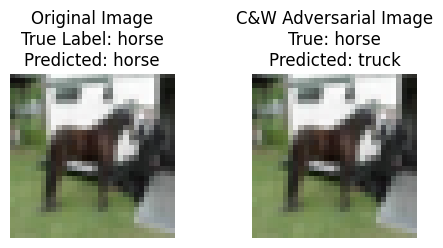

In [38]:
# Visual of one example
class_names = train_dataset.classes

img_idx = 20

true_label = class_names[y_attack[img_idx]]
clean_pred_label = class_names[clean_pred_classes[img_idx]]
adv_pred_label = class_names[adv_pred_classes[img_idx]]

plt.figure(figsize=(5, 2.5))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(np.transpose(x_attack[img_idx], (1, 2, 0)))
plt.title(f"Original Image\nTrue Label: {true_label}\nPredicted: {clean_pred_label}")
plt.axis('off')

# C&W Image
plt.subplot(1, 2, 2)
plt.imshow(np.transpose(x_adv[img_idx], (1, 2, 0)))
plt.title(f"C&W Adversarial Image\nTrue: {true_label}\nPredicted: {adv_pred_label}")
plt.axis('off')

plt.tight_layout()
plt.show()


# Attack Peformance Observation on Model A
- Model A's clean accuracy on 500 samples: 82.20%, Clean F1: 0.8196
- C&W Attack: 12.60% adversarial accuracy, F1: 0.1201, average L2 Distance: 0.1387
- This attack significantly lowered Model A's accuracy by about 70 percentage points, making it an effective attack


In [39]:
# Attack 1: Carlini & Wagner L2 Attack on Model B

# Wrap Model B for ART to "test" transferability (adv images from Model A into Model B)
classifier_b = PyTorchClassifier(
    model=model_b, # The model being attacked
    loss=criterion, # CrossEntropyLoss
    optimizer=optimizer_b, # Adam Optimizer
    input_shape=(3, 32, 32), # 3 color channels, 32x32 pixels
    nb_classes=10, # 10 classes
    clip_values=(0.0,1.0) # pixel values to range [0.0, 1.0]
)

In [40]:
# Now evaluate Model B on 500 clean images
clean_pred_b = classifier_b.predict(x_attack)
clean_pred_classes_b = np.argmax(clean_pred_b, axis=1)
clean_accuracy_b = np.mean(clean_pred_classes_b == y_attack) * 100

print(f"Model B Clean Accuracy on 500 samples: {clean_accuracy_b:.2f}%")

Model B Clean Accuracy on 500 samples: 71.60%


In [41]:
# Test the 500 C&W adv imgs generated using Model A on Model B
adv_pred_b = classifier_b.predict(x_adv)
adv_pred_classes_b = np.argmax(adv_pred_b, axis=1)
adv_accuracy_b = np.mean(adv_pred_classes_b == y_attack)*100

print(f"Model B Adversarial Accuracy on 500 samples: {adv_accuracy_b:.2f}%")

Model B Adversarial Accuracy on 500 samples: 70.80%


# C&W Transferability Observation on Model B
- Model B's clean accuracy on 500 samples: 71.60%
- C&W transferred adversarial accuracy: 70.80%
- Accuracy decreased by only 0.80 percentage points
- Therefore, the black-box transferability wasn't very effective on Model B from Model A

Attack 2: DeepFool

In [43]:
# Attack 2: DeepFool attack on Model A
from art.attacks.evasion import DeepFool

df_attack = DeepFool(
    classifier=classifier_a,
    max_iter=10,
    epsilon=0.02,
    nb_grads=10,
    batch_size=32
)

# Generate DF adv imgs
x_adv2 = df_attack.generate(x=x_attack)

print(f"Adversarial images shape: {x_adv2.shape}")

DeepFool:   0%|          | 0/16 [00:00<?, ?it/s]

Adversarial images shape: (500, 3, 32, 32)


In [44]:
# Now evaluate Model A on the generated adv imgs
adv_pred2 = classifier_a.predict(x_adv2)
adv_pred_classes2 = np.argmax(adv_pred2, axis=1)
adv_accuracy2 = np.mean(adv_pred_classes2 == y_attack)*100

print(f"Model A Adversarial Accuracy on 500 samples: {adv_accuracy2:.2f}%")

Model A Adversarial Accuracy on 500 samples: 12.40%


In [45]:
# Compare accuracy drop
accuracy_drop2 = clean_accuracy - adv_accuracy2

# Calculate L2 perturbation distance for each img
perturbation2 = x_attack - x_adv2
perturbation_distance2 = np.linalg.norm(perturbation2.reshape(len(perturbation2), -1), axis=1)

# Average L2 distances across all 500 imgs
avg_perturbation_distance2 = np.mean(perturbation_distance2)

print(f"Accuracy Drop: {accuracy_drop2:.2f}%")
print(f"Average L2 Perturbation Distance: {avg_perturbation_distance2:.4f}")

# Calculate F1 scores
adv_f1_2 = f1_score(y_attack, adv_pred_classes2, average='macro')

print(f"Clean F1 Score: {clean_f1:.4f}")
print(f"DeepFool Adversarial F1 Score: {adv_f1_2:.4f}")



Accuracy Drop: 69.80%
Average L2 Perturbation Distance: 0.1484
Clean F1 Score: 0.8196
DeepFool Adversarial F1 Score: 0.1187


# DeepFool Attack Observation on Model A
- Model A's clean accuracy on 500 samples: 82.20%, Clean F1: 0.8196
- DeepFool Attack: 12.40% adversarial accuracy, F1: 0.1187, average L2 Distance: 0.1484
- DeepFool also significantly lowered Model A's accuracy by a huge percantage point, making it an effective attack

In [46]:
# Test the 500 DeepFool adv imgs generated using Model A on Model B
adv_pred_b2 = classifier_b.predict(x_adv2)
adv_pred_classes_b2 = np.argmax(adv_pred_b2, axis=1)
adv_accuracy_b2 = np.mean(adv_pred_classes_b2 == y_attack)*100

print(f"Model B DeepFool Adversarial Accuracy on 500 samples: {adv_accuracy_b2:.2f}%")

Model B DeepFool Adversarial Accuracy on 500 samples: 70.80%


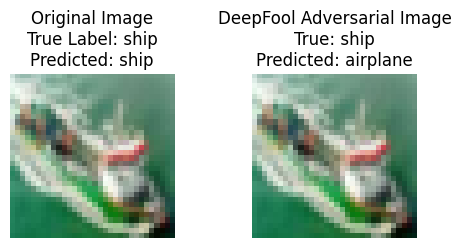

In [47]:
# Visual of one DeepFool example
class_names = train_dataset.classes

img_idx = 15

true_label = class_names[y_attack[img_idx]]
clean_pred_label = class_names[clean_pred_classes[img_idx]]
adv_pred_label2 = class_names[adv_pred_classes2[img_idx]]

plt.figure(figsize=(5, 2.5))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(np.transpose(x_attack[img_idx], (1, 2, 0)))
plt.title(f"Original Image\nTrue Label: {true_label}\nPredicted: {clean_pred_label}")
plt.axis('off')

# DF Image
plt.subplot(1, 2, 2)
plt.imshow(np.transpose(x_adv2[img_idx], (1, 2, 0)))
plt.title(f"DeepFool Adversarial Image\nTrue: {true_label}\nPredicted: {adv_pred_label2}")
plt.axis('off')

plt.tight_layout()
plt.show()


#DeepFool Transferability Observation on Model B
- Model B's clean accuracy on 500 samples: 71.60%
- DeepFool transferred adversarial accuracy: 70.80%
- Accuracy also decreased by 0.80 percentage points
- Therefore, the black-box transferrability on Model B from Model A was not very effective

Defenses

In [59]:
# Defense 1: Adversarial Training
import copy

# Create a copy of Model A
model_a_adv = copy.deepcopy(model_a)
model_a_adv = model_a_adv.to(device)

optimizer_adv = optim.Adam(model_a_adv.parameters(), lr=0.001)

# Adversarial Training Hyperparameters
adv_portion = 0.25 # % of each training batch will be adversarial
adv_epochs = 1

In [62]:
# Wrap defended model for ART
classifier_adv = PyTorchClassifier(
    model=model_a_adv, # The model being adv. trained
    loss=criterion, # CrossEntropyLoss
    optimizer=optimizer_adv, # Adam Optimizer
    input_shape=(3, 32, 32), # 3 color channels, 32x32 pixels
    nb_classes=10, # 10 classes
    clip_values=(0.0,1.0) # pixel values to range [0.0, 1.0]
)

df_train_attack = DeepFool(
    classifier=classifier_adv,
    max_iter=3,
    epsilon=0.02,
    nb_grads=10,
    batch_size=32,
    verbose=False
)

# Now do the adv training
adversarial_training(
    model=model_a_adv,
    train_loader=train_loader,
    attack=df_train_attack,
    optimizer=optimizer_adv,
    criterion=criterion,
    adv_portion=adv_portion,
    epochs=adv_epochs
)

Epoch 1/1:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch [1/1], Loss: 0.4133, Accuracy: 69.91%


In [63]:
# Now evaluate defended Model A on 500 clean images
clean_pred_adv = classifier_adv.predict(x_attack)
clean_pred_classes_adv = np.argmax(clean_pred_adv, axis=1)
clean_accuracy_adv = np.mean(clean_pred_classes_adv == y_attack) * 100

print(f"Original Model A Clean Accuracy on 500 samples: {clean_accuracy:.2f}%")
print(f"Defended Model A Clean Accuracy on 500 samples: {clean_accuracy_adv:.2f}%")

Original Model A Clean Accuracy on 500 samples: 82.20%
Defended Model A Clean Accuracy on 500 samples: 82.20%


In [64]:
# Attack the defended Model A with C&W
cw_attack_adv = CarliniL2Method(
    classifier=classifier_adv, # Attack defended model A
    confidence=0.0,
    learning_rate=0.01,
    binary_search_steps=5,
    max_iter=10,
    batch_size=32
)

# Generate new adv examples against defended model
x_adv_cw_defended = cw_attack_adv.generate(x=x_attack)

# Pred on defended model
cw_defended_pred = classifier_adv.predict(x_adv_cw_defended)
cw_defended_pred_classes = np.argmax(cw_defended_pred, axis=1)
# Calcuate accuracy after c&W attack
cw_defended_accuracy = np.mean(cw_defended_pred_classes == y_attack) * 100

print(f"Defended Model Clean Accuracy: {clean_accuracy_adv:.2f}%")
print(f"Defended Model A Adversarial Accuracy on 500 samples: {cw_defended_accuracy:.2f}%")

C&W L_2:   0%|          | 0/16 [00:00<?, ?it/s]

Defended Model Clean Accuracy: 82.20%
Defended Model A Adversarial Accuracy on 500 samples: 22.00%


In [65]:
# Attack the defended model A with DeepFool
df_attack_adv = DeepFool(
    classifier=classifier_adv,
    max_iter=10,
    epsilon=0.02,
    nb_grads=10,
    batch_size=32,
    verbose=False
)

# Generate new DF adv imgs
x_adv_df_defended = df_attack_adv.generate(x=x_attack)

# Pred on defended Model A
df_defended_pred = classifier_adv.predict(x_adv_df_defended)
df_defended_pred_classes = np.argmax(df_defended_pred, axis=1)

# Calcuate accuracy after DF attack
df_defended_accuracy = np.mean(df_defended_pred_classes == y_attack) * 100

print(f"Defended Model Clean Accuracy: {clean_accuracy_adv:.2f}%")
print(f"Defended Model A DeepFool Accuracy on 500 samples: {df_defended_accuracy:.2f}%")

Defended Model Clean Accuracy: 82.20%
Defended Model A DeepFool Accuracy on 500 samples: 11.40%


# Adversarial Training Defense Observation
- Hyperparamter tuning: 25% adverarial training portion, 1 epoch, DeepFool max_iter = 3
- Clean accuracy remained at 82.20% after adversarial training
- C&W adversarial accuracy improved from 12.60% to 22.00% with the use of this method
- While this improved under C&W attack, adverarial accuracy for DeepFool decreased from 12.40% to 11.40%
- Because the adversarial training took longer, the parameters were reduced

In [68]:
# Defense 2: Distillation
t_model = model_a
t_model.eval()

s_model = resnet18(weights=None)

s_model.conv1 = nn.Conv2d(3,  # Number of channels (input)
                          64, # output channels
                          kernel_size=3,
                          stride=1,
                          padding=1,
                          bias=False)
s_model.maxpool = nn.Identity()

s_model.fc = nn.Linear(s_model.fc.in_features, 10)

s_model = s_model.to(device)

# Distillation hyperparams
temp = 10
d_epochs = 2
optimizer_s = optim.Adam(s_model.parameters(), lr=0.001)

# Training
distillation_training(
    t=t_model,
    s=s_model,
    train_loader=train_loader,
    optimizer=optimizer_s,
    temp=temp,
    epochs=d_epochs
)


Epoch 1/2:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch [1/2], Loss: 13.1803, Accuracy: 55.55%


Epoch 2/2:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch [2/2], Loss: 5.3934, Accuracy: 75.82%


In [69]:
# Now evaluate distilled model on 500 clean imgs
s_model.eval()

with torch.no_grad():
  outputs_s = s_model(torch.tensor(x_attack, dtype=torch.float32).to(device))

  pred_classes_s = torch.argmax(outputs_s, dim=1).cpu().numpy()

  clean_accuracy_s = np.mean(pred_classes_s == y_attack) * 100

print(f"Original Model Clean Accuracy: {clean_accuracy:.2f}%")
print(f"Distilled Model Clean Accuracy on 500 samples: {clean_accuracy_s:.2f}%")

Original Model Clean Accuracy: 82.20%
Distilled Model Clean Accuracy on 500 samples: 74.80%


In [70]:
# Wrap distilled model for ART
classifier_distilled = PyTorchClassifier(
    model=s_model, # The distilled model
    loss=criterion,
    optimizer=optimizer_s,
    input_shape=(3, 32, 32),
    nb_classes=10,
    clip_values=(0.0,1.0)
)

# C&w attack against distilled
cw_attack_distilled = CarliniL2Method(
    classifier=classifier_distilled,
    confidence=0.0,
    learning_rate=0.01,
    binary_search_steps=5,
    max_iter=10,
    batch_size=32
)

# Generate new C&W adv samples against distilled model
x_adv_cw_distilled = cw_attack_distilled.generate(x=x_attack)

# Pred on distilled model
cw_distilled_pred = classifier_distilled.predict(x_adv_cw_distilled)
cw_distilled_pred_classes = np.argmax(cw_distilled_pred, axis=1)

# Calcuate accuracy after c&W attack
cw_distilled_accuracy = np.mean(cw_distilled_pred_classes == y_attack) * 100

print(f"Distilled Model Clean Accuracy: {clean_accuracy_s:.2f}%")
print(f"Distilled Model C&W Adversarial Accuracy on 500 samples: {cw_distilled_accuracy:.2f}%")

C&W L_2:   0%|          | 0/16 [00:00<?, ?it/s]

Distilled Model Clean Accuracy: 74.80%
Distilled Model C&W Adversarial Accuracy on 500 samples: 13.40%


In [71]:
# Attack the distilled model with DeepFool
df_attack_dis = DeepFool(
    classifier=classifier_distilled,
    max_iter=10,
    epsilon=0.02,
    nb_grads=10,
    batch_size=32,
    verbose=False
)

# Generate new DF adv imgs
x_adv_df_dis = df_attack_dis.generate(x=x_attack)

# Pred on defended Model A
df_dis_pred = classifier_distilled.predict(x_adv_df_dis)
df_dis_pred_classes = np.argmax(df_dis_pred, axis=1)

# Calcuate accuracy after DF attack
df_dis_accuracy = np.mean(df_dis_pred_classes == y_attack) * 100

print(f"Distilled Model Clean Accuracy: {clean_accuracy_s:.2f}%")
print(f"Distilled Model DeepFool Adv Accuracy on 500 samples: {df_dis_accuracy:.2f}%")

Distilled Model Clean Accuracy: 74.80%
Distilled Model DeepFool Adv Accuracy on 500 samples: 13.20%


# Distilled Defense Observation
- Hyperparameter tuning: Temperature = 10, 2 training epochs
- Clean accuracy decreased from 82.20% to 74.80% after distillation
- C&W adversarial accuracy slightly improved from 12.60% to 13.40%
- DeepFool adversarial accuracy slightly improved from 12.40% to 13.20%
- Distillation made small improvements against both attacks, however there was lower clean accuracy